In [6]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Import Required Libraries

In [7]:
import pandas as pd
import numpy as np
import re
import unicodedata


# Define File Paths

In [ ]:
# Input dataset path
DATA_PATH = '/content/drive/MyDrive/Assamese_Sentiment_Analysis/Data/Assamese_Movie_Review_Shuffled_8987.csv'

# Output path for cleaned dataset
OUTPUT_PATH = '/content/drive/MyDrive/Assamese_Sentiment_Analysis/Data/Assamese_Movie_Review_Cleaned_8987.csv'


# Load Dataset

In [ ]:
df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (8987, 3)


,ID,Reviews,Sentiment
0,0,বোকা নাটক,negative
1,1,নাটকখন বৰ ধুনীয়া আছিল।,positive
2,2,এখন ভাল ঘৰ এনে হ'ব লাগে,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive
4,4,মই বহুদিন অপেক্ষা কৰি আছো........ অৱশেষত দেখিল...,positive


# Basic Dataset Validation

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8987 entries, 0 to 8986
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         8987 non-null   int64 
 1   Reviews    8987 non-null   object
 2   Sentiment  8987 non-null   object
dtypes: int64(1), object(2)
memory usage: 210.8+ KB


In [ ]:
# Check for missing values
df.isnull().sum()


,0
ID,0
Reviews,0
Sentiment,0


In [ ]:
# Ensure expected columns
assert set(df.columns) == {'ID', 'Reviews', 'Sentiment'}, "Unexpected column names"


# Unicode Normalization Function (Critical for Assamese)

In [ ]:
def normalize_unicode(text):
    return unicodedata.normalize('NFC', text)


# Text Cleaning Function

In [ ]:
import re

def clean_text(text):
    """
    Cleans Assamese text by:
    - Removing unwanted special characters (% # @ etc.)
    - Keeping Assamese, English, digits, and basic punctuation (. , ! ? :)
    - Reducing repeated punctuation to a single instance
    - Removing leading punctuation at the start of the review
    - Ensuring sentences end with only one valid punctuation mark
    """
    if isinstance(text, str):
        # 1. Remove everything except Assamese, English, digits, spaces, and punctuation
        text = re.sub(r"[^অ-৺a-zA-Z0-9\s.,!?;:]", "", text)

        # 2. Replace multiple punctuation (e.g., "!!!", ",,,,") with a single one
        text = re.sub(r"([.,!?;:])\1+", r"\1", text)

        # 3. Remove punctuation if repeated (like ",,,!") → keep last valid one
        text = re.sub(r"([.,!?;:]){2,}", r"\1", text)

        # 4. Remove leading punctuation (e.g., ", বছ" → "বছ")
        text = re.sub(r"^[.,!?;:\s]+", "", text)

        # 5. Normalize spaces
        text = re.sub(r"\s+", " ", text).strip()

        return text
    return ""

# Apply cleaning to review column
df['Reviews'] = df['Reviews'].apply(clean_text)

df.head()

,ID,Reviews,Sentiment
0,0,বোকা নাটক,negative
1,1,নাটকখন বৰ ধুনীয়া আছিল,positive
2,2,এখন ভাল ঘৰ এনে হব লাগে,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive
4,4,মই বহুদিন অপেক্ষা কৰি আছো. অৱশেষত দেখিলো. কেৱল...,positive


# Applying Preprocessing

In [ ]:
df['Reviews'] = df['Reviews'].apply(clean_text)

df.head()


,ID,Reviews,Sentiment
0,0,বোকা নাটক,negative
1,1,নাটকখন বৰ ধুনীয়া আছিল,positive
2,2,এখন ভাল ঘৰ এনে হব লাগে,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive
4,4,মই বহুদিন অপেক্ষা কৰি আছো. অৱশেষত দেখিলো. কেৱল...,positive


In [ ]:
final_df = df[['ID', 'Reviews', 'Sentiment']]

final_df.info()
final_df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8987 entries, 0 to 8986
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         8987 non-null   int64 
 1   Reviews    8987 non-null   object
 2   Sentiment  8987 non-null   object
dtypes: int64(1), object(2)
memory usage: 210.8+ KB


,ID,Reviews,Sentiment
0,0,বোকা নাটক,negative
1,1,নাটকখন বৰ ধুনীয়া আছিল,positive
2,2,এখন ভাল ঘৰ এনে হব লাগে,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive
4,4,মই বহুদিন অপেক্ষা কৰি আছো. অৱশেষত দেখিলো. কেৱল...,positive


# Save Cleaned dataset

In [ ]:
final_df.to_csv(OUTPUT_PATH, index=False, encoding='utf-8')

print("Cleaned dataset saved with original column names at:")
print(OUTPUT_PATH)


Cleaned dataset saved with original column names at:
/content/drive/MyDrive/Assamese_Sentiment_Analysis/Data/Assamese_Movie_Review_Cleaned_8987.csv


In [8]:
# Another dataset path
DATA_PATH_EXTRA = '/content/drive/MyDrive/Assamese_Sentiment_Analysis/Data/Assamese_Movie_Review_8987_Labelled by 2 Annotators.csv'




In [9]:
df_new = pd.read_csv(DATA_PATH_EXTRA)

print("Dataset Shape:", df_new.shape)
df_new.head()


Dataset Shape: (8987, 4)


,ID,Reviews,Annotator 1 Sentiment,Annotator 2 Sentiment
0,0,বোকা নাটক,negative,positive
1,1,নাটকখন বৰ ধুনীয়া আছিল,positive,positive
2,2,এখন ভাল ঘৰ এনে হব লাগে,positive,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive,positive
4,4,মই বহুদিন অপেক্ষা কৰি আছো. অৱশেষত দেখিলো. কেৱল...,positive,positive


In [10]:
from sklearn.metrics import cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Make a copy and drop rows where either sentiment column has missing values
# This ensures we only compare valid annotations and handle mixed types.
cleaned_df = df_new.dropna(subset=['Annotator 1 Sentiment', 'Annotator 2 Sentiment']).copy()

# Explicitly convert sentiment columns to string type
sentiment_annotator_1 = cleaned_df['Annotator 1 Sentiment'].astype(str)
sentiment_annotator_2 = cleaned_df['Annotator 2 Sentiment'].astype(str)

# Calculate Cohen's Kappa score
kappa = cohen_kappa_score(sentiment_annotator_1, sentiment_annotator_2)

# Interpret the Kappa score
if kappa < 0:
    agreement_interpretation = "Poor agreement"
elif kappa < 0.21:
    agreement_interpretation = "Slight agreement"
elif kappa < 0.41:
    agreement_interpretation = "Fair agreement"
elif kappa < 0.61:
    agreement_interpretation = "Moderate agreement"
elif kappa < 0.81:
    agreement_interpretation = "Substantial agreement"
else:
    agreement_interpretation = "Almost perfect agreement"

print(f"Cohen's Kappa Score: {kappa:.3f}")
print(f"Interpretation: {agreement_interpretation}")

Cohen's Kappa Score: 0.942
Interpretation: Almost perfect agreement


### Confusion Matrix for Actual Annotator Agreement

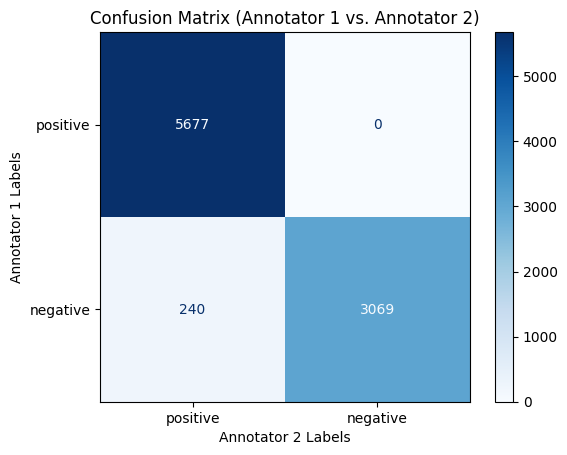

In [11]:
# Generate the confusion matrix
# Using the cleaned and string-converted sentiment data from the previous cell
cm = confusion_matrix(sentiment_annotator_1, sentiment_annotator_2, labels=['positive', 'negative'])

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['positive', 'negative'])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix (Annotator 1 vs. Annotator 2)')
plt.xlabel('Annotator 2 Labels')
plt.ylabel('Annotator 1 Labels')
plt.show()